In [1]:
from pathlib import Path
import json
import math
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm
from ultralytics import YOLO

Пути

In [2]:
dataset_path = Path(r"C:\Users\Ева\Desktop\Хакатон\data_preproc\constraction_labelme")

images_path = dataset_path / "images"
labels_path = dataset_path / "labels"

# # Папка проекта YOLO-World
# world_path = Path(r"Yolo-world")
# yolov8x-worldv2.pt
# Куда сохранять эксперименты
results_root = Path(r"yoloworld_experiments_8x")

results_root.mkdir(parents=True, exist_ok=True)

print("Датасет:", dataset_path)
print("Изображения:", images_path)
print("Разметка:", labels_path)
print("Результаты:", results_root)

Датасет: C:\Users\Ева\Desktop\Хакатон\data_preproc\constraction_labelme
Изображения: C:\Users\Ева\Desktop\Хакатон\data_preproc\constraction_labelme\images
Разметка: C:\Users\Ева\Desktop\Хакатон\data_preproc\constraction_labelme\labels
Результаты: yoloworld_experiments_8x


Классы

In [3]:
eval_classes = [
    "truck",
    "excavator",
    "concrete mixer"
]

label_to_class = {
    "грузовик": "truck",
    "экскаватор": "excavator",
    "бетономешалка": "concrete mixer"
}

class_to_id = {
    class_name: i
    for i, class_name in enumerate(eval_classes)
}

class_to_id

{'truck': 0, 'excavator': 1, 'concrete mixer': 2}

Загрузка Ground Truth

In [4]:
json_files = sorted(labels_path.glob("*.json"))

print("Количество JSON:", len(json_files))

ground_truth = {}

for json_file in tqdm(json_files, desc="Загрузка разметки"):
    
    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)
    
    image_stem = json_file.stem
    
    objects = []
    
    for shape in data.get("shapes", []):
        
        label_ru = shape["label"]
        
        if label_ru not in label_to_class:
            continue
        
        points = np.array(shape["points"], dtype=float)
        
        x1 = points[:, 0].min()
        y1 = points[:, 1].min()
        x2 = points[:, 0].max()
        y2 = points[:, 1].max()
        
        class_name = label_to_class[label_ru]
        
        objects.append({
            "class": class_name,
            "original_class": label_ru,
            "bbox": [
                float(x1),
                float(y1),
                float(x2),
                float(y2)
            ]
        })
    
    ground_truth[image_stem] = objects

print("Изображений с разметкой:", len(ground_truth))

Количество JSON: 3651


Загрузка разметки:   0%|          | 0/3651 [00:00<?, ?it/s]

Загрузка разметки: 100%|██████████| 3651/3651 [00:01<00:00, 2138.23it/s]

Изображений с разметкой: 3651


In [5]:
image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}

image_files = sorted(
    [
        p for p in images_path.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]
)

print("Количество изображений:", len(image_files))

Количество изображений: 3651


In [7]:
model = YOLO("yolov8x-worldv2.pt")

print("Модель загружена")

Модель загружена


In [8]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA доступна:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.0+cu126
CUDA доступна: True
GPU: NVIDIA GeForce RTX 3070 Laptop GPU


Наборы промптов

In [9]:
experiments = {
    
    "01_baseline": [
        "truck",
        "excavator",
        "concrete mixer"
    ],
    
    "02_vehicle": [
        "truck vehicle",
        "excavator vehicle",
        "concrete mixer truck"
    ],
    
    "03_complete": [
        "a complete truck vehicle",
        "a complete excavator vehicle",
        "a complete concrete mixer truck"
    ],
    
    "04_construction": [
        "construction truck",
        "construction excavator",
        "concrete mixer truck"
    ],
    
    "05_heavy_equipment": [
        "heavy truck",
        "excavator construction machine",
        "concrete mixer truck"
    ],
    
    "06_specific": [
        "a road truck",
        "a tracked excavator",
        "a concrete mixer truck"
    ]
}

for experiment_name, prompts in experiments.items():
    print(experiment_name)
    for class_name, prompt in zip(eval_classes, prompts):
        print(f"  {class_name:20s} → {prompt}")
    print()

01_baseline
  truck                → truck
  excavator            → excavator
  concrete mixer       → concrete mixer

02_vehicle
  truck                → truck vehicle
  excavator            → excavator vehicle
  concrete mixer       → concrete mixer truck

03_complete
  truck                → a complete truck vehicle
  excavator            → a complete excavator vehicle
  concrete mixer       → a complete concrete mixer truck

04_construction
  truck                → construction truck
  excavator            → construction excavator
  concrete mixer       → concrete mixer truck

05_heavy_equipment
  truck                → heavy truck
  excavator            → excavator construction machine
  concrete mixer       → concrete mixer truck

06_specific
  truck                → a road truck
  excavator            → a tracked excavator
  concrete mixer       → a concrete mixer truck



Параметры оценки

In [10]:
CONF_THRESHOLD = 0.1

IOU_THRESHOLD = 0.5

# Для mAP считаем IoU от 0.50 до 0.95 с шагом 0.05
MAP_IOU_THRESHOLDS = np.arange(
    0.50,
    0.96,
    0.05
)

# Толщина рамки на сохранённых изображениях
LINE_WIDTH = 2

print("Confidence:", CONF_THRESHOLD)
print("IoU:", IOU_THRESHOLD)
print("mAP thresholds:", MAP_IOU_THRESHOLDS)

Confidence: 0.1
IoU: 0.5
mAP thresholds: [        0.5        0.55         0.6        0.65         0.7        0.75         0.8        0.85         0.9        0.95]


# IoU

In [11]:
def calculate_iou(box1, box2):
    """
    box = [x1, y1, x2, y2]
    """
    
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    
    intersection_width = max(0, x2 - x1)
    intersection_height = max(0, y2 - y1)
    
    intersection = intersection_width * intersection_height
    
    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])
    
    union = area1 + area2 - intersection
    
    if union <= 0:
        return 0.0
    
    return intersection / union

# TP / FP / FN

In [12]:
def evaluate_at_iou(
    predictions,
    ground_truth,
    classes,
    iou_threshold=0.5,
    conf_threshold=0.1
):
    
    stats = {
        class_name: {
            "TP": 0,
            "FP": 0,
            "FN": 0
        }
        for class_name in classes
    }
    
    for image_stem, gt_objects in ground_truth.items():
        
        image_predictions = predictions.get(image_stem, [])
        
        # Оставляем только достаточно уверенные предсказания
        image_predictions = [
            pred
            for pred in image_predictions
            if pred["confidence"] >= conf_threshold
        ]
        
        # Обрабатываем каждый класс отдельно
        for class_name in classes:
            
            gt_boxes = [
                obj["bbox"]
                for obj in gt_objects
                if obj["class"] == class_name
            ]
            
            pred_boxes = [
                pred
                for pred in image_predictions
                if pred["class"] == class_name
            ]
            
            # Сначала самые уверенные предсказания
            pred_boxes = sorted(
                pred_boxes,
                key=lambda x: x["confidence"],
                reverse=True
            )
            
            matched_gt = set()
            
            for pred in pred_boxes:
                
                best_iou = 0
                best_gt_idx = None
                
                for gt_idx, gt_box in enumerate(gt_boxes):
                    
                    if gt_idx in matched_gt:
                        continue
                    
                    iou = calculate_iou(
                        pred["bbox"],
                        gt_box
                    )
                    
                    if iou > best_iou:
                        best_iou = iou
                        best_gt_idx = gt_idx
                
                if best_iou >= iou_threshold:
                    
                    stats[class_name]["TP"] += 1
                    matched_gt.add(best_gt_idx)
                
                else:
                    
                    stats[class_name]["FP"] += 1
            
            stats[class_name]["FN"] += (
                len(gt_boxes) - len(matched_gt)
            )
    
    return stats

# Метрики Precision / Recall / F1

In [13]:
def calculate_prf(tp, fp, fn):
    
    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0.0
    )
    
    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0.0
    )
    
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )
    
    return precision, recall, f1

# AP

In [14]:
def calculate_ap(
    predictions,
    ground_truth,
    class_name,
    iou_threshold
):
    
    # Все предсказания данного класса
    all_predictions = []
    
    for image_stem, image_preds in predictions.items():
        
        for pred in image_preds:
            
            if pred["class"] == class_name:
                
                all_predictions.append({
                    "image": image_stem,
                    "confidence": pred["confidence"],
                    "bbox": pred["bbox"]
                })
    
    # Сортируем по confidence
    all_predictions.sort(
        key=lambda x: x["confidence"],
        reverse=True
    )
    
    # Ground Truth по изображениям
    gt_by_image = {}
    
    for image_stem, objects in ground_truth.items():
        
        gt_by_image[image_stem] = [
            obj["bbox"]
            for obj in objects
            if obj["class"] == class_name
        ]
    
    # Сколько всего GT объектов
    total_gt = sum(
        len(boxes)
        for boxes in gt_by_image.values()
    )
    
    if total_gt == 0:
        return 0.0
    
    matched = {
        image_stem: set()
        for image_stem in gt_by_image
    }
    
    tp = np.zeros(len(all_predictions))
    fp = np.zeros(len(all_predictions))
    
    for i, pred in enumerate(all_predictions):
        
        image_stem = pred["image"]
        pred_box = pred["bbox"]
        
        gt_boxes = gt_by_image.get(image_stem, [])
        
        best_iou = 0
        best_gt_idx = None
        
        for gt_idx, gt_box in enumerate(gt_boxes):
            
            if gt_idx in matched[image_stem]:
                continue
            
            iou = calculate_iou(
                pred_box,
                gt_box
            )
            
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = gt_idx
        
        if best_iou >= iou_threshold:
            
            tp[i] = 1
            matched[image_stem].add(best_gt_idx)
            
        else:
            
            fp[i] = 1
    
    cumulative_tp = np.cumsum(tp)
    cumulative_fp = np.cumsum(fp)
    
    recalls = cumulative_tp / total_gt
    
    precisions = cumulative_tp / (
        cumulative_tp + cumulative_fp + 1e-12
    )
    
    # Добавляем крайние точки
    recalls = np.concatenate(
        ([0.0], recalls, [1.0])
    )
    
    precisions = np.concatenate(
        ([1.0], precisions, [0.0])
    )
    
    # Precision envelope
    for i in range(len(precisions) - 2, -1, -1):
        precisions[i] = max(
            precisions[i],
            precisions[i + 1]
        )
    
    # 101-point interpolation
    recall_points = np.linspace(0, 1, 101)
    
    precision_at_recall = []
    
    for recall_point in recall_points:
        
        valid = np.where(
            recalls >= recall_point
        )[0]
        
        if len(valid) > 0:
            precision_at_recall.append(
                np.max(precisions[valid])
            )
        else:
            precision_at_recall.append(0.0)
    
    ap = np.mean(precision_at_recall)
    
    return float(ap)

# mAP

In [15]:
def calculate_map_metrics(
    predictions,
    ground_truth,
    classes
):
    
    ap_by_iou = {}
    
    for iou_threshold in MAP_IOU_THRESHOLDS:
        
        threshold_name = f"{iou_threshold:.2f}"
        
        class_aps = {}
        
        for class_name in classes:
            
            ap = calculate_ap(
                predictions,
                ground_truth,
                class_name,
                iou_threshold
            )
            
            class_aps[class_name] = ap
        
        ap_by_iou[threshold_name] = class_aps
    
    # AP50 по классам
    ap50_by_class = ap_by_iou["0.50"]
    
    map50 = np.mean(
        list(ap50_by_class.values())
    )
    
    # mAP 50-95
    all_ap_values = []
    
    for threshold_data in ap_by_iou.values():
        all_ap_values.extend(
            threshold_data.values()
        )
    
    map50_95 = np.mean(all_ap_values)
    
    return {
        "AP50_by_class": ap50_by_class,
        "mAP50": float(map50),
        "mAP50-95": float(map50_95),
        "AP_by_IoU": ap_by_iou
    }

# Один эксперимент

In [16]:
# ==========================================
# Один эксперимент
# ==========================================

def run_experiment(
    experiment_name,
    prompts,
    model,
    image_files,
    ground_truth,
    results_root,
    eval_classes,
    conf_threshold=0.1,
    iou_threshold=0.5
):
    
    print("=" * 70)
    print(f"ЭКСПЕРИМЕНТ: {experiment_name}")
    print("=" * 70)
    
    print("\nПромпты:")
    
    for class_name, prompt in zip(eval_classes, prompts):
        print(f"  {class_name:20s} → {prompt}")
    
    # --------------------------------------
    # Папки эксперимента
    # --------------------------------------
    
    experiment_path = results_root / experiment_name
    images_result_path = experiment_path / "images"
    
    images_result_path.mkdir(
        parents=True,
        exist_ok=True
    )
    
    # --------------------------------------
    # Устанавливаем классы YOLO-World
    # --------------------------------------
    
    model.set_classes(prompts)
    
    # --------------------------------------
    # Predictions
    # --------------------------------------
    
    all_predictions = {}
    
    for image_file in tqdm(
        image_files,
        desc=experiment_name
    ):
        
        image_stem = image_file.stem
        
        results = model.predict(
            source=str(image_file),
            conf=conf_threshold,
            verbose=False
        )
        
        result = results[0]
        
        image_predictions = []
        
        if result.boxes is not None:
            
            boxes = result.boxes
            
            for i in range(len(boxes)):
                
                cls_id = int(
                    boxes.cls[i].item()
                )
                
                confidence = float(
                    boxes.conf[i].item()
                )
                
                bbox = boxes.xyxy[i].cpu().numpy().tolist()
                
                # Индекс класса соответствует
                # индексу промпта
                if cls_id >= len(eval_classes):
                    continue
                
                class_name = eval_classes[cls_id]
                
                image_predictions.append({
                    "class": class_name,
                    "confidence": confidence,
                    "bbox": [
                        float(x)
                        for x in bbox
                    ]
                })
        
        all_predictions[image_stem] = image_predictions
        
        # ----------------------------------
        # Сохраняем изображение
        # ----------------------------------
        
        plotted = result.plot(
            line_width=LINE_WIDTH,
            labels=True,
            boxes=True,
            conf=True
        )
        
        output_image = images_result_path / image_file.name
        
        import cv2
        
        cv2.imwrite(
            str(output_image),
            plotted
        )
    
    # --------------------------------------
    # Сохраняем predictions.json
    # --------------------------------------
    
    predictions_path = (
        experiment_path / "predictions.json"
    )
    
    with open(
        predictions_path,
        "w",
        encoding="utf-8"
    ) as f:
        
        json.dump(
            all_predictions,
            f,
            ensure_ascii=False,
            indent=2
        )
    
    # --------------------------------------
    # Считаем количество GT объектов
    # --------------------------------------
    
    total_gt_objects = 0
    
    for image_file in image_files:
        
        image_stem = image_file.stem
        
        total_gt_objects += len(
            ground_truth.get(image_stem, [])
        )
    
    # --------------------------------------
    # TP / FP / FN
    # --------------------------------------
    
    stats = evaluate_at_iou(
        predictions=all_predictions,
        ground_truth=ground_truth,
        classes=eval_classes,
        iou_threshold=iou_threshold,
        conf_threshold=conf_threshold
    )
    
    # --------------------------------------
    # Precision / Recall / F1
    # --------------------------------------
    
    metrics_by_class = {}
    
    for class_name in eval_classes:
        
        tp = stats[class_name]["TP"]
        fp = stats[class_name]["FP"]
        fn = stats[class_name]["FN"]
        
        precision, recall, f1 = calculate_prf(
            tp,
            fp,
            fn
        )
        
        metrics_by_class[class_name] = {
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        }
    
    # --------------------------------------
    # mAP
    # --------------------------------------
    
    map_metrics = calculate_map_metrics(
        predictions=all_predictions,
        ground_truth=ground_truth,
        classes=eval_classes
    )
    
    # --------------------------------------
    # Macro average
    # --------------------------------------
    
    mean_precision = np.mean([
        x["Precision"]
        for x in metrics_by_class.values()
    ])
    
    mean_recall = np.mean([
        x["Recall"]
        for x in metrics_by_class.values()
    ])
    
    mean_f1 = np.mean([
        x["F1"]
        for x in metrics_by_class.values()
    ])
    
    # --------------------------------------
    # Общие TP / FP / FN
    # --------------------------------------
    
    total_tp = sum(
        x["TP"]
        for x in metrics_by_class.values()
    )
    
    total_fp = sum(
        x["FP"]
        for x in metrics_by_class.values()
    )
    
    total_fn = sum(
        x["FN"]
        for x in metrics_by_class.values()
    )
    
    overall_precision, overall_recall, overall_f1 = calculate_prf(
        total_tp,
        total_fp,
        total_fn
    )
    
    # --------------------------------------
    # Финальный metrics.json
    # --------------------------------------
    
    metrics = {
        "experiment": experiment_name,
        
        "prompts": {
            class_name: prompt
            for class_name, prompt
            in zip(eval_classes, prompts)
        },
        
        "parameters": {
            "confidence_threshold": conf_threshold,
            "iou_threshold": iou_threshold
        },
        
        "dataset": {
            "images": len(image_files),
            "ground_truth_objects": total_gt_objects
        },
        
        "overall": {
            "TP": total_tp,
            "FP": total_fp,
            "FN": total_fn,
            "Precision": overall_precision,
            "Recall": overall_recall,
            "F1": overall_f1
        },
        
        "macro_average": {
            "Precision": float(mean_precision),
            "Recall": float(mean_recall),
            "F1": float(mean_f1)
        },
        
        "per_class": metrics_by_class,
        
        "mAP": map_metrics
    }
    
    # --------------------------------------
    # Сохраняем metrics.json
    # --------------------------------------
    
    metrics_path = (
        experiment_path / "metrics.json"
    )
    
    with open(
        metrics_path,
        "w",
        encoding="utf-8"
    ) as f:
        
        json.dump(
            metrics,
            f,
            ensure_ascii=False,
            indent=2
        )
    
    # --------------------------------------
    # Вывод результатов
    # --------------------------------------
    
    print("\nГотово.")
    
    print("Predictions:", predictions_path)
    print("Metrics:", metrics_path)
    
    print("\nОбщие метрики:")
    print(f"Precision : {overall_precision:.4f}")
    print(f"Recall    : {overall_recall:.4f}")
    print(f"F1        : {overall_f1:.4f}")
    print(f"mAP50     : {map_metrics['mAP50']:.4f}")
    print(f"mAP50-95  : {map_metrics['mAP50-95']:.4f}")
    
    print("\nПо классам:")
    
    for class_name, class_metrics in metrics_by_class.items():
        
        print(
            f"{class_name:20s} "
            f"P={class_metrics['Precision']:.4f}  "
            f"R={class_metrics['Recall']:.4f}  "
            f"F1={class_metrics['F1']:.4f}"
        )
    
    return all_predictions, metrics

# ТЕСТ

In [17]:
test_image_files = image_files[:50]

print("Для теста используется:", len(test_image_files))

Для теста используется: 50


In [18]:
predictions_test, metrics_test = run_experiment(
    experiment_name="01_baseline_test",
    prompts=experiments["01_baseline"],
    model=model,
    image_files=test_image_files,
    ground_truth=ground_truth,
    results_root=results_root,
    eval_classes=eval_classes,
    conf_threshold=CONF_THRESHOLD,
    iou_threshold=IOU_THRESHOLD
)

ЭКСПЕРИМЕНТ: 01_baseline_test

Промпты:
  truck                → truck
  excavator            → excavator
  concrete mixer       → concrete mixer


c:\Users\Ева\Desktop\Хакатон\venv\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
01_baseline_test: 100%|██████████| 50/50 [00:04<00:00, 10.84it/s]



Готово.
Predictions: yoloworld_experiments_8x\01_baseline_test\predictions.json
Metrics: yoloworld_experiments_8x\01_baseline_test\metrics.json

Общие метрики:
Precision : 0.5227
Recall    : 0.0092
F1        : 0.0180
mAP50     : 0.0132
mAP50-95  : 0.0120

По классам:
truck                P=0.4066  R=0.0091  F1=0.0178
excavator            P=0.7805  R=0.0136  F1=0.0267
concrete mixer       P=0.0000  R=0.0000  F1=0.0000


In [19]:
# ==========================================
# Проверка тестового эксперимента
# ==========================================

print("Эксперимент:", metrics_test["experiment"])

print("\nОбщие метрики:")
print(
    f"Precision : {metrics_test['overall']['Precision']:.4f}"
)
print(
    f"Recall    : {metrics_test['overall']['Recall']:.4f}"
)
print(
    f"F1        : {metrics_test['overall']['F1']:.4f}"
)
print(
    f"mAP50     : {metrics_test['mAP']['mAP50']:.4f}"
)
print(
    f"mAP50-95  : {metrics_test['mAP']['mAP50-95']:.4f}"
)

print("\nПо классам:")

for class_name, values in metrics_test["per_class"].items():
    print(
        f"{class_name:20s} "
        f"P={values['Precision']:.4f}  "
        f"R={values['Recall']:.4f}  "
        f"F1={values['F1']:.4f}"
    )

Эксперимент: 01_baseline_test

Общие метрики:
Precision : 0.5227
Recall    : 0.0092
F1        : 0.0180
mAP50     : 0.0132
mAP50-95  : 0.0120

По классам:
truck                P=0.4066  R=0.0091  F1=0.0178
excavator            P=0.7805  R=0.0136  F1=0.0267
concrete mixer       P=0.0000  R=0.0000  F1=0.0000


In [20]:
# ==========================================
# Проверка сохранения
# ==========================================

test_experiment_path = results_root / "01_baseline_test"

print("Папка эксперимента:")
print(test_experiment_path)

print("\nФайлы:")

for path in sorted(test_experiment_path.rglob("*")):
    if path.is_file():
        print(path.relative_to(test_experiment_path))

Папка эксперимента:
yoloworld_experiments_8x\01_baseline_test

Файлы:
images\000001_jpg.rf.758184e127cbc907e8c8cc8dd9974125.jpg
images\000002_jpg.rf.626da3bdb96939a56d459e81100c4f20.jpg
images\000003_jpg.rf.08f9c3e9904a0fd81423b998eb8296be.jpg
images\000004_jpg.rf.028897721b46d58d12918685d78cadaf.jpg
images\000005_jpg.rf.1a09355b2d3a2be217107e830e72bb87.jpg
images\000006_jpg.rf.2e7bbffdf578b480f0491e15a3327a42.jpg
images\000007_jpg.rf.f45cb224610eddcc679ab6acc8b191f2.jpg
images\000008_jpg.rf.c5e43a3b652fbeb3c93408b03cfc82d4.jpg
images\000009_jpg.rf.4295b97e8dec25cc53b932e2ece01ec7.jpg
images\000010_jpg.rf.762da09d09e78db09092f3f5cee88288.jpg
images\000011_jpg.rf.5dc981d2c2361dc75512a587bbcb0a54.jpg
images\000012_jpg.rf.64bdc4bd12dd20543fa51c5f04c6b255.jpg
images\000013_jpg.rf.5c709dba4ce1b54fe016dacdd9ae516f.jpg
images\000014_jpg.rf.80c12ad7fdd9d72be8502c420a832396.jpg
images\000015_jpg.rf.5c6d9bd880824d50272266605d7598db.jpg
images\000016_jpg.rf.dd19c44fbb2420347c653dabdca18b22.jpg
im

In [21]:
# ==========================================
# Пример predictions.json
# ==========================================

first_image = next(iter(predictions_test))

print("Изображение:", first_image)
print()

print(
    json.dumps(
        predictions_test[first_image],
        ensure_ascii=False,
        indent=2
    )
)

Изображение: 000001_jpg.rf.758184e127cbc907e8c8cc8dd9974125

[
  {
    "class": "truck",
    "confidence": 0.7823941707611084,
    "bbox": [
      30.15741539001465,
      169.3447723388672,
      235.29608154296875,
      291.18017578125
    ]
  },
  {
    "class": "excavator",
    "confidence": 0.6905419826507568,
    "bbox": [
      172.15647888183594,
      19.50922393798828,
      399.6028137207031,
      303.5640869140625
    ]
  }
]


In [22]:
# ==========================================
# Пример Ground Truth
# ==========================================

print("Изображение:", first_image)
print()

print(
    json.dumps(
        ground_truth[first_image],
        ensure_ascii=False,
        indent=2
    )
)

Изображение: 000001_jpg.rf.758184e127cbc907e8c8cc8dd9974125

[
  {
    "class": "excavator",
    "original_class": "экскаватор",
    "bbox": [
      173.0,
      19.0,
      398.0,
      302.0
    ]
  },
  {
    "class": "truck",
    "original_class": "грузовик",
    "bbox": [
      31.0,
      168.0,
      233.0,
      289.0
    ]
  }
]


# ПОЛНЫЙ ЗАПУСК ВСЕХ ЭКСПЕРИМЕНТОВ

In [23]:
all_experiment_metrics = {}

for experiment_name, prompts in experiments.items():
    
    predictions, metrics = run_experiment(
        experiment_name=experiment_name,
        prompts=prompts,
        model=model,
        image_files=image_files,
        ground_truth=ground_truth,
        results_root=results_root,
        eval_classes=eval_classes,
        conf_threshold=CONF_THRESHOLD,
        iou_threshold=IOU_THRESHOLD
    )
    
    all_experiment_metrics[experiment_name] = metrics

ЭКСПЕРИМЕНТ: 01_baseline

Промпты:
  truck                → truck
  excavator            → excavator
  concrete mixer       → concrete mixer


01_baseline: 100%|██████████| 3651/3651 [03:02<00:00, 20.01it/s]



Готово.
Predictions: yoloworld_experiments_8x\01_baseline\predictions.json
Metrics: yoloworld_experiments_8x\01_baseline\metrics.json

Общие метрики:
Precision : 0.5004
Recall    : 0.5074
F1        : 0.5039
mAP50     : 0.3424
mAP50-95  : 0.2543

По классам:
truck                P=0.4102  R=0.4580  F1=0.4328
excavator            P=0.6307  R=0.8253  F1=0.7150
concrete mixer       P=0.7500  R=0.0161  F1=0.0315
ЭКСПЕРИМЕНТ: 02_vehicle

Промпты:
  truck                → truck vehicle
  excavator            → excavator vehicle
  concrete mixer       → concrete mixer truck


02_vehicle: 100%|██████████| 3651/3651 [03:32<00:00, 17.15it/s]



Готово.
Predictions: yoloworld_experiments_8x\02_vehicle\predictions.json
Metrics: yoloworld_experiments_8x\02_vehicle\metrics.json

Общие метрики:
Precision : 0.3864
Recall    : 0.5802
F1        : 0.4638
mAP50     : 0.3992
mAP50-95  : 0.2924

По классам:
truck                P=0.4081  R=0.4555  F1=0.4305
excavator            P=0.4493  R=0.8932  F1=0.5979
concrete mixer       P=0.1985  R=0.3721  F1=0.2589
ЭКСПЕРИМЕНТ: 03_complete

Промпты:
  truck                → a complete truck vehicle
  excavator            → a complete excavator vehicle
  concrete mixer       → a complete concrete mixer truck


...


Готово.
Predictions: yoloworld_experiments_8x\04_construction\predictions.json
Metrics: yoloworld_experiments_8x\04_construction\metrics.json

Общие метрики:
Precision : 0.4134
Recall    : 0.5487
F1        : 0.4716
mAP50     : 0.3549
mAP50-95  : 0.2479

По классам:
truck                P=0.3549  R=0.4861  F1=0.4103
excavator            P=0.6845  R=0.7304  F1=0.7067
concrete mixer       P=0.2279  R=0.3927  F1=0.2884
ЭКСПЕРИМЕНТ: 05_heavy_equipment

Промпты:
  truck                → heavy truck
  excavator            → excavator construction machine
  concrete mixer       → concrete mixer truck


05_heavy_equipment: 100%|██████████| 3651/3651 [03:52<00:00, 15.68it/s]



Готово.
Predictions: yoloworld_experiments_8x\05_heavy_equipment\predictions.json
Metrics: yoloworld_experiments_8x\05_heavy_equipment\metrics.json

Общие метрики:
Precision : 0.3811
Recall    : 0.5445
F1        : 0.4484
mAP50     : 0.3405
mAP50-95  : 0.2452

По классам:
truck                P=0.3205  R=0.5314  F1=0.3998
excavator            P=0.7832  R=0.6922  F1=0.7349
concrete mixer       P=0.1604  R=0.2800  F1=0.2040
ЭКСПЕРИМЕНТ: 06_specific

Промпты:
  truck                → a road truck
  excavator            → a tracked excavator
  concrete mixer       → a concrete mixer truck


06_specific: 100%|██████████| 3651/3651 [03:55<00:00, 15.49it/s]



Готово.
Predictions: yoloworld_experiments_8x\06_specific\predictions.json
Metrics: yoloworld_experiments_8x\06_specific\metrics.json

Общие метрики:
Precision : 0.4038
Recall    : 0.4660
F1        : 0.4327
mAP50     : 0.4328
mAP50-95  : 0.3164

По классам:
truck                P=0.6778  R=0.1903  F1=0.2972
excavator            P=0.4280  R=0.8436  F1=0.5678
concrete mixer       P=0.2577  R=0.6699  F1=0.3723


# Общий summary JSON

In [24]:
summary_json_path = (
    results_root / "experiments_summary.json"
)

with open(
    summary_json_path,
    "w",
    encoding="utf-8"
) as f:
    
    json.dump(
        all_experiment_metrics,
        f,
        ensure_ascii=False,
        indent=2
    )

print("Сохранено:")
print(summary_json_path)

Сохранено:
yoloworld_experiments_8x\experiments_summary.json


# Таблица экспериментов

In [25]:
summary_rows = []

for experiment_name, metrics in all_experiment_metrics.items():
    
    row = {
        "experiment": experiment_name,
        
        "Precision": metrics["overall"]["Precision"],
        "Recall": metrics["overall"]["Recall"],
        "F1": metrics["overall"]["F1"],
        
        "mAP50": metrics["mAP"]["mAP50"],
        "mAP50-95": metrics["mAP"]["mAP50-95"],
    }
    
    # AP50 каждого класса
    for class_name, ap in metrics["mAP"]["AP50_by_class"].items():
        row[f"AP50_{class_name}"] = ap
    
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)

summary_df

,experiment,Precision,Recall,F1,mAP50,mAP50-95,AP50_truck,AP50_excavator,AP50_concrete mixer
0,01_baseline,0.500393,0.507433,0.503888,0.342394,0.254282,0.260362,0.747678,0.019142
1,02_vehicle,0.386370,0.580170,0.463840,0.399234,0.292443,0.240486,0.747130,0.210087
2,03_complete,0.404945,0.536899,0.461679,0.416372,0.299592,0.196073,0.665612,0.387429
3,04_construction,0.413441,0.548713,0.471568,0.354944,0.247865,0.194013,0.649542,0.221278
4,05_heavy_equipment,0.381085,0.544465,0.448355,0.340468,0.245246,0.229756,0.650407,0.141242
5,06_specific,0.403795,0.466021,0.432682,0.432765,0.316422,0.151051,0.683227,0.464018


# Сортировка по mAP50-95

In [26]:
# ==========================================
# ==========================================

summary_sorted = summary_df.sort_values(
    "mAP50-95",
    ascending=False
).reset_index(drop=True)

summary_sorted

,experiment,Precision,Recall,F1,mAP50,mAP50-95,AP50_truck,AP50_excavator,AP50_concrete mixer
0,06_specific,0.403795,0.466021,0.432682,0.432765,0.316422,0.151051,0.683227,0.464018
1,03_complete,0.404945,0.536899,0.461679,0.416372,0.299592,0.196073,0.665612,0.387429
2,02_vehicle,0.386370,0.580170,0.463840,0.399234,0.292443,0.240486,0.747130,0.210087
3,01_baseline,0.500393,0.507433,0.503888,0.342394,0.254282,0.260362,0.747678,0.019142
4,04_construction,0.413441,0.548713,0.471568,0.354944,0.247865,0.194013,0.649542,0.221278
5,05_heavy_equipment,0.381085,0.544465,0.448355,0.340468,0.245246,0.229756,0.650407,0.141242


# Сохранение CSV

In [27]:
summary_csv_path = (
    results_root / "experiments_summary.csv"
)

summary_df.to_csv(
    summary_csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("Сохранено:")
print(summary_csv_path)

Сохранено:
yoloworld_experiments_8x\experiments_summary.csv


# Таблица промптов

In [28]:
prompt_rows = []

for experiment_name, prompts in experiments.items():
    
    row = {
        "experiment": experiment_name
    }
    
    for class_name, prompt in zip(eval_classes, prompts):
        row[class_name] = prompt
    
    prompt_rows.append(row)

prompts_df = pd.DataFrame(prompt_rows)

prompts_df

,experiment,truck,excavator,concrete mixer
0,01_baseline,truck,excavator,concrete mixer
1,02_vehicle,truck vehicle,excavator vehicle,concrete mixer truck
2,03_complete,a complete truck vehicle,a complete excavator vehicle,a complete concrete mixer truck
3,04_construction,construction truck,construction excavator,concrete mixer truck
4,05_heavy_equipment,heavy truck,excavator construction machine,concrete mixer truck
5,06_specific,a road truck,a tracked excavator,a concrete mixer truck


# Сохранение промптов

In [29]:
prompts_csv_path = (
    results_root / "experiments_prompts.csv"
)

prompts_df.to_csv(
    prompts_csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("Сохранено:")
print(prompts_csv_path)

Сохранено:
yoloworld_experiments_8x\experiments_prompts.csv


# Precision / Recall / F1

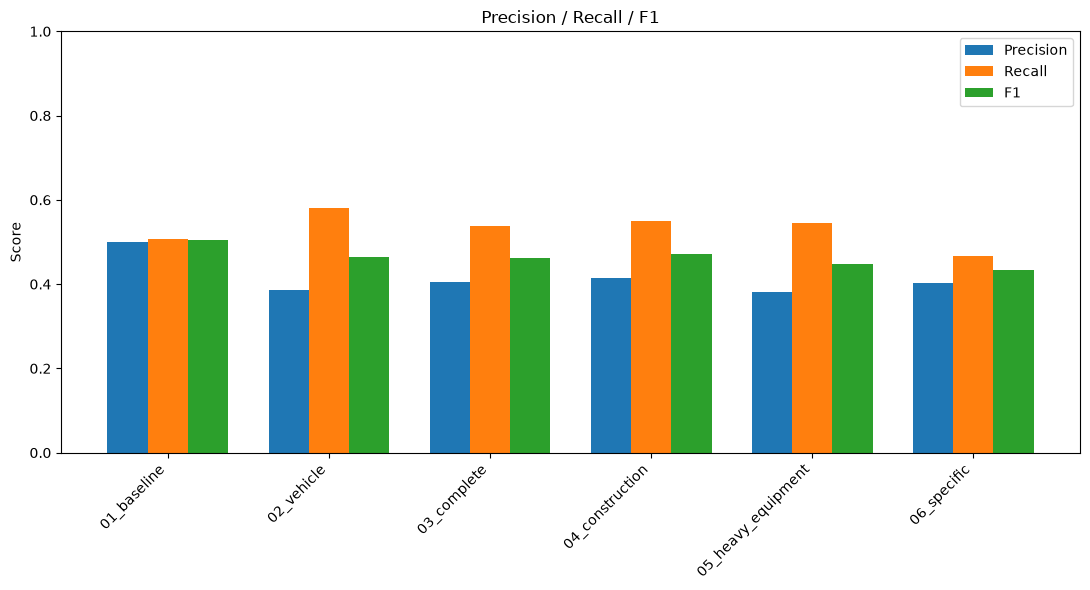

In [30]:
plt.figure(figsize=(11, 6))

x = np.arange(len(summary_df))
width = 0.25

plt.bar(
    x - width,
    summary_df["Precision"],
    width,
    label="Precision"
)

plt.bar(
    x,
    summary_df["Recall"],
    width,
    label="Recall"
)

plt.bar(
    x + width,
    summary_df["F1"],
    width,
    label="F1"
)

plt.xticks(
    x,
    summary_df["experiment"],
    rotation=45,
    ha="right"
)

plt.ylabel("Score")
plt.title("Precision / Recall / F1")
plt.ylim(0, 1)

plt.legend()
plt.tight_layout()
plt.show()

# mAP50 / mAP50-95

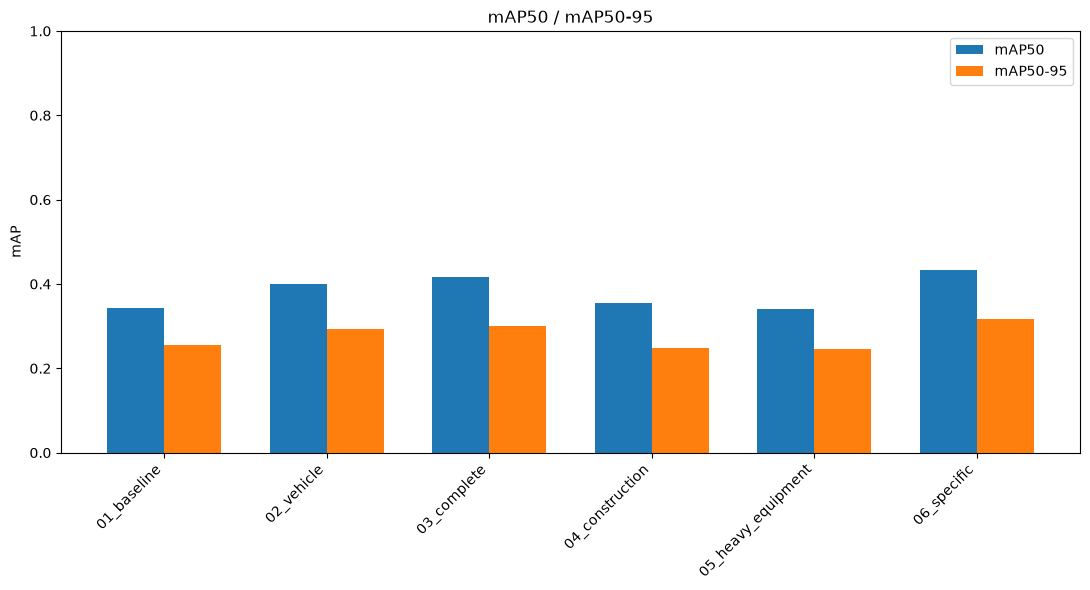

In [31]:
plt.figure(figsize=(11, 6))

x = np.arange(len(summary_df))
width = 0.35

plt.bar(
    x - width / 2,
    summary_df["mAP50"],
    width,
    label="mAP50"
)

plt.bar(
    x + width / 2,
    summary_df["mAP50-95"],
    width,
    label="mAP50-95"
)

plt.xticks(
    x,
    summary_df["experiment"],
    rotation=45,
    ha="right"
)

plt.ylabel("mAP")
plt.title("mAP50 / mAP50-95")
plt.ylim(0, 1)

plt.legend()
plt.tight_layout()
plt.show()

# AP50 по классам

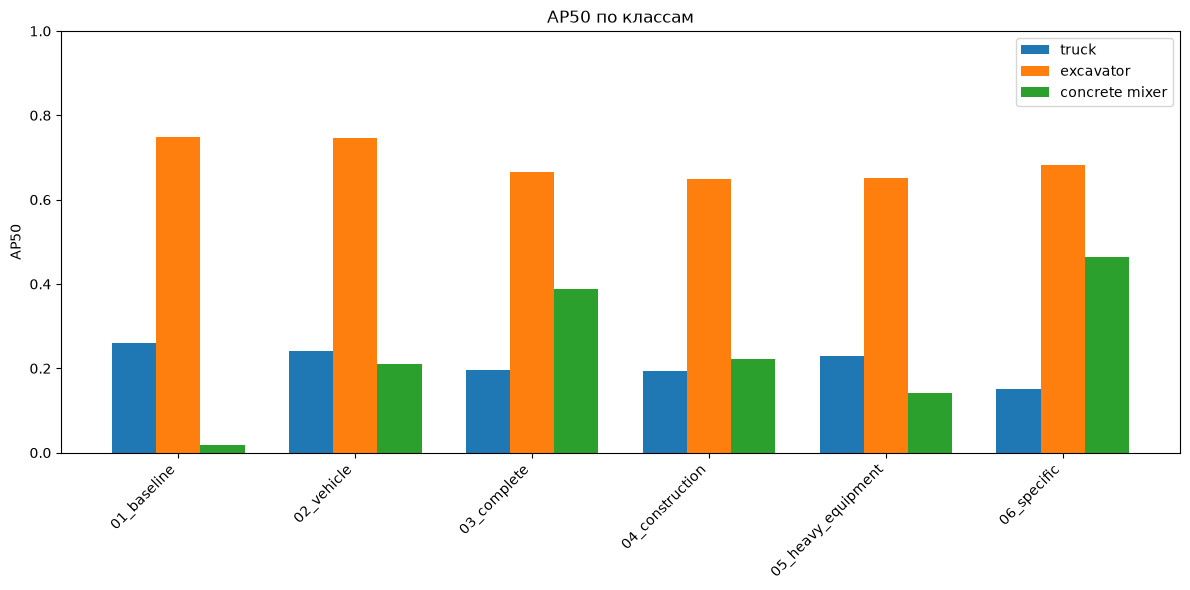

In [32]:
plt.figure(figsize=(12, 6))

x = np.arange(len(summary_df))
width = 0.25

for i, class_name in enumerate(eval_classes):
    
    column = f"AP50_{class_name}"
    
    plt.bar(
        x + (i - 1) * width,
        summary_df[column],
        width,
        label=class_name
    )

plt.xticks(
    x,
    summary_df["experiment"],
    rotation=45,
    ha="right"
)

plt.ylabel("AP50")
plt.title("AP50 по классам")
plt.ylim(0, 1)

plt.legend()
plt.tight_layout()
plt.show()

# TP / FP / FN

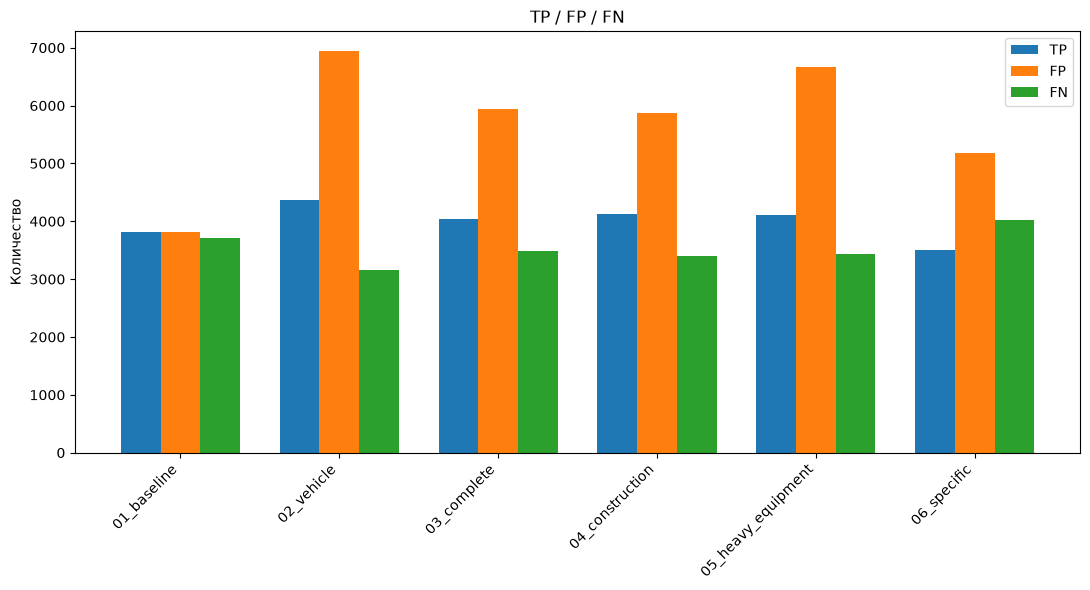

In [33]:
tp_values = []
fp_values = []
fn_values = []

for experiment_name in summary_df["experiment"]:
    
    metrics = all_experiment_metrics[experiment_name]
    
    tp_values.append(metrics["overall"]["TP"])
    fp_values.append(metrics["overall"]["FP"])
    fn_values.append(metrics["overall"]["FN"])

x = np.arange(len(summary_df))
width = 0.25

plt.figure(figsize=(11, 6))

plt.bar(
    x - width,
    tp_values,
    width,
    label="TP"
)

plt.bar(
    x,
    fp_values,
    width,
    label="FP"
)

plt.bar(
    x + width,
    fn_values,
    width,
    label="FN"
)

plt.xticks(
    x,
    summary_df["experiment"],
    rotation=45,
    ha="right"
)

plt.ylabel("Количество")
plt.title("TP / FP / FN")
plt.legend()

plt.tight_layout()
plt.show()